# 1. Define Q-network, Replay Buffer

이 단계의 핵심은 다음과 같습니다.
- QNetwork: 상태 4개를 입력받아 두 행동의 Q-value를 출력합니다.
- ReplayBuffer: 과거 상태 전이 경험을 저장하고 무작위로 추출합니다.
- target_net: 안정적인 TD target 계산을 위해 별도로 유지합니다.
- get_epsilon: 학습이 진행될수록 무작위 행동의 비율을 감소시킵니다.

In [29]:
import os
import random
import copy
import numpy as np
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque

OUTPUT_DIR = "cartpole_dqn_output"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
CHECKPOINT_EPISODES = [1, 100, 500, 750, 1000]
EPISODES = 1000
BATCH_SIZE = 64
GAMMA = 0.99
LEARNING_RATE = 1e-3
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY = 0.995
TARGET_UPDATE = 10
BUFFER_SIZE = 50000
SEED = 123

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class DQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.network(x)

env = gym.make("CartPole-v1")
env.action_space.seed(SEED)

policy_net = DQN().to(device)
target_net = DQN().to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
replay_buffer = deque(maxlen=BUFFER_SIZE)

episode_rewards = []
episode_losses = []
snapshots = {}

epsilon = EPSILON_START

for episode in range(1, EPISODES + 1):
    state, _ = env.reset(seed=SEED + episode)
    total_reward = 0
    current_episode_losses = []
    done = False

    while not done:
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_tensor = torch.as_tensor(
                    state, dtype=torch.float32, device=device
                ).unsqueeze(0)
                action = policy_net(state_tensor).argmax(dim=1).item()

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        replay_buffer.append((
            state,
            action,
            reward,
            next_state,
            float(done)
        ))

        state = next_state
        total_reward += reward

        if len(replay_buffer) >= BATCH_SIZE:
            batch = random.sample(replay_buffer, BATCH_SIZE)
            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.as_tensor(
                np.asarray(states), dtype=torch.float32, device=device
            )
            actions = torch.as_tensor(
                actions, dtype=torch.long, device=device
            ).unsqueeze(1)
            rewards = torch.as_tensor(
                rewards, dtype=torch.float32, device=device
            )
            next_states = torch.as_tensor(
                np.asarray(next_states), dtype=torch.float32, device=device
            )
            dones = torch.as_tensor(
                dones, dtype=torch.float32, device=device
            )

            current_q = policy_net(states).gather(1, actions).squeeze(1)

            with torch.no_grad():
                next_q = target_net(next_states).max(dim=1).values
                target_q = rewards + GAMMA * next_q * (1 - dones)

            loss = nn.functional.smooth_l1_loss(current_q, target_q)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(policy_net.parameters(), 10.0)
            optimizer.step()

            current_episode_losses.append(loss.item())

    epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    episode_rewards.append(total_reward)
    episode_losses.append(
        float(np.mean(current_episode_losses))
        if current_episode_losses else np.nan
    )

    if episode % TARGET_UPDATE == 0:
        target_net.load_state_dict(policy_net.state_dict())

    if episode in CHECKPOINT_EPISODES:
        checkpoint_path = os.path.join(
            CHECKPOINT_DIR, f"dqn_episode_{episode}.pt"
        )
        snapshots[f"DQN Episode {episode}"] = copy.deepcopy(
            policy_net.state_dict()
        )
        torch.save(policy_net.state_dict(), checkpoint_path)
        print(f"Saved checkpoint: episode={episode}, reward={total_reward}")

    if episode % 50 == 0 or episode in CHECKPOINT_EPISODES:
        print(
            f"Episode {episode:4d} | "
            f"Reward {total_reward:6.1f} | "
            f"Mean50 {np.mean(episode_rewards[-50:]):6.1f} | "
            f"Loss {episode_losses[-1]:.6f} | "
            f"Epsilon {epsilon:.3f}"
        )

env.close()

np.savez(
    os.path.join(OUTPUT_DIR, "dqn_training_history.npz"),
    episode_rewards=np.asarray(episode_rewards, dtype=float),
    episode_losses=np.asarray(episode_losses, dtype=float)
)

print("Training complete.")
print("History saved:", os.path.join(OUTPUT_DIR, "dqn_training_history.npz"))
print("Checkpoints saved:", CHECKPOINT_DIR)


Device: cuda
Saved checkpoint: episode=1, reward=14.0
Episode    1 | Reward   14.0 | Mean50   14.0 | Loss nan | Epsilon 0.995
Episode   50 | Reward   18.0 | Mean50   23.4 | Loss 0.066606 | Epsilon 0.778
Saved checkpoint: episode=100, reward=49.0
Episode  100 | Reward   49.0 | Mean50   38.9 | Loss 0.134879 | Epsilon 0.606
Episode  150 | Reward   15.0 | Mean50   81.4 | Loss 0.080311 | Epsilon 0.471
Episode  200 | Reward   59.0 | Mean50   40.6 | Loss 0.191992 | Epsilon 0.367
Episode  250 | Reward   12.0 | Mean50   32.6 | Loss 0.280794 | Epsilon 0.286
Episode  300 | Reward    8.0 | Mean50   45.8 | Loss 0.536118 | Epsilon 0.222
Episode  350 | Reward   68.0 | Mean50   83.4 | Loss 0.365052 | Epsilon 0.173
Episode  400 | Reward   99.0 | Mean50   75.3 | Loss 0.378140 | Epsilon 0.135
Episode  450 | Reward   98.0 | Mean50   90.5 | Loss 0.387104 | Epsilon 0.105
Saved checkpoint: episode=500, reward=107.0
Episode  500 | Reward  107.0 | Mean50   95.1 | Loss 0.487562 | Epsilon 0.082
Episode  550 | Re

# 2. DQN 학습 및 학습 전후 영상 기록 함수
이 단계에서는 매 에피소드마다 얻은 보상을 기록하고, 최근 100개 에피소드의 평균 보상이 475 이상이면 학습을 종료합니다. 기준에 도달하지 못하면 최대 600 에피소드까지 학습합니다.

In [30]:

import os
import numpy as np
import imageio.v2 as imageio
import gymnasium as gym
import torch
from PIL import Image, ImageDraw, ImageFont

OUTPUT_DIR = "cartpole_dqn_output"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
VIDEO_SEED = 123
VIDEO_FPS = 30
VIDEO_FRAMES = 500
WIDTH = 480
HEIGHT = 320
FALL_FRAMES = 45
REQUESTED_EPISODES = [1, 100, 500, 750, 1000]

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

try:
    font = ImageFont.truetype("DejaVuSans.ttf", 15)
except OSError:
    font = ImageFont.load_default()

class DQN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.network = torch.nn.Sequential(
            torch.nn.Linear(4, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.network(x)

def get_snapshot(target_episode):
    path = os.path.join(
        CHECKPOINT_DIR, f"dqn_episode_{target_episode}.pt"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"체크포인트가 없습니다: {path}. Step 1을 먼저 실행하세요."
        )

    state_dict = torch.load(path, map_location=device, weights_only=True)
    return target_episode, state_dict

video_specs = [("Before training", None, None)]

for requested_episode in REQUESTED_EPISODES:
    actual_episode, policy_state = get_snapshot(requested_episode)
    video_specs.append(
        (f"Training episode {actual_episode}", policy_state, actual_episode)
    )

def make_policy(policy_state):
    if policy_state is None:
        return None

    model = DQN().to(device)
    model.load_state_dict(policy_state)
    model.eval()
    return model

def render_cartpole(state, label, frame_idx, reward, failed, failure_frame=None, fall_angle=None):
    x, _, theta, _ = state
    image = Image.new("RGB", (WIDTH, HEIGHT), (245, 247, 250))
    draw = ImageDraw.Draw(image)

    track_y = 250
    draw.line((20, track_y, WIDTH - 20, track_y), fill=(70, 70, 70), width=4)

    cart_x = int(WIDTH / 2 + np.clip(x, -2.4, 2.4) * 90)
    cart_y = track_y - 25
    cart_w = 54
    cart_h = 30

    draw.rectangle(
        (
            cart_x - cart_w // 2,
            cart_y - cart_h // 2,
            cart_x + cart_w // 2,
            cart_y + cart_h // 2
        ),
        fill=(60, 100, 180),
        outline=(20, 40, 80),
        width=2
    )

    wheel_y = cart_y + 19
    draw.ellipse((cart_x - 17, wheel_y - 7, cart_x - 3, wheel_y + 7), fill=(35, 35, 35))
    draw.ellipse((cart_x + 3, wheel_y - 7, cart_x + 17, wheel_y + 7), fill=(35, 35, 35))

    pivot_x = cart_x
    pivot_y = cart_y - cart_h // 2
    pole_len = 105
    theta_to_draw = theta if fall_angle is None else fall_angle

    tip_x = int(pivot_x + pole_len * np.sin(theta_to_draw))
    tip_y = int(pivot_y - pole_len * np.cos(theta_to_draw))

    pole_color = (220, 55, 45) if failed else (30, 150, 75)
    draw.line((pivot_x, pivot_y, tip_x, tip_y), fill=pole_color, width=9)
    draw.ellipse(
        (pivot_x - 7, pivot_y - 7, pivot_x + 7, pivot_y + 7),
        fill=(30, 30, 30)
    )

    draw.text((10, 8), label, font=font, fill=(20, 20, 20))
    draw.text(
        (10, 29),
        f"Frame: {frame_idx + 1}/{VIDEO_FRAMES} | Reward: {reward:.0f}",
        font=font,
        fill=(20, 20, 20)
    )

    if failed:
        draw.text(
            (10, 50),
            f"FAILED at frame {failure_frame + 1}",
            font=font,
            fill=(200, 30, 30)
        )

    return np.asarray(image)

def record_episode(policy_state, label, filename):
    env = gym.make("CartPole-v1")
    state, _ = env.reset(seed=VIDEO_SEED)
    model = make_policy(policy_state)
    rng = np.random.default_rng(VIDEO_SEED)

    total_reward = 0
    failed = False
    failure_state = None
    failure_frame = None

    with imageio.get_writer(
        filename,
        fps=VIDEO_FPS,
        codec="libx264",
        quality=8,
        macro_block_size=16
    ) as writer:
        for t in range(VIDEO_FRAMES):
            fall_angle = None

            if not failed:
                if model is None:
                    action = int(rng.integers(0, 2))
                else:
                    with torch.no_grad():
                        state_tensor = torch.as_tensor(
                            state, dtype=torch.float32, device=device
                        ).unsqueeze(0)
                        action = model(state_tensor).argmax(dim=1).item()

                next_state, reward, terminated, truncated, _ = env.step(action)
                state = next_state
                total_reward += reward

                if terminated or truncated:
                    failed = True
                    failure_state = np.array(state, dtype=float).copy()
                    failure_frame = t
            else:
                elapsed = t - failure_frame
                initial_angle = float(failure_state[2])
                direction = 1 if initial_angle >= 0 else -1
                target_angle = direction * (np.pi * 0.95)
                progress = min(1.0, elapsed / FALL_FRAMES)
                smooth_progress = progress * progress * (3 - 2 * progress)
                fall_angle = initial_angle * (1 - smooth_progress) + target_angle * smooth_progress

                state = failure_state.copy()
                state[2] = fall_angle

            frame = render_cartpole(
                state, label, t, total_reward, failed, failure_frame, fall_angle
            )
            writer.append_data(frame)

    env.close()
    return total_reward, failure_frame

clip_paths = []
results = []

for i, (label, policy_state, episode) in enumerate(video_specs, start=1):
    path = os.path.join(OUTPUT_DIR, f"cartpole_clip_{i}.mp4")
    reward, failure_frame = record_episode(policy_state, label, path)

    clip_paths.append(path)
    results.append((label, reward, failure_frame))

    print(
        f"{label} | reward={reward:.0f} | "
        f"failure frame={failure_frame + 1 if failure_frame is not None else 'none'}"
    )

print("Individual clips:", clip_paths)


Before training | reward=19 | failure frame=19
Training episode 1 | reward=10 | failure frame=10
Training episode 100 | reward=201 | failure frame=201
Training episode 500 | reward=117 | failure frame=117
Training episode 750 | reward=500 | failure frame=500
Training episode 1000 | reward=106 | failure frame=106
Individual clips: ['cartpole_dqn_output/cartpole_clip_1.mp4', 'cartpole_dqn_output/cartpole_clip_2.mp4', 'cartpole_dqn_output/cartpole_clip_3.mp4', 'cartpole_dqn_output/cartpole_clip_4.mp4', 'cartpole_dqn_output/cartpole_clip_5.mp4', 'cartpole_dqn_output/cartpole_clip_6.mp4']


# 3단계. 학습 전후 비교 영상 생성
학습 전후 영상은 각각 저장되어 있습니다. 이제 두 영상을 좌우로 결합합니다.

In [31]:

import os
import numpy as np
import imageio.v2 as imageio
from PIL import Image

OUTPUT_DIR = "cartpole_dqn_output"
VIDEO_FPS = 30
VIDEO_FRAMES = 500
WIDTH = 480
HEIGHT = 320

clip_paths = [
    os.path.join(OUTPUT_DIR, f"cartpole_clip_{i}.mp4")
    for i in range(1, 7)
]

for path in clip_paths:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"영상 파일이 없습니다: {path}. Step 2를 먼저 실행하세요."
        )

readers = [imageio.get_reader(path) for path in clip_paths]
montage_path = os.path.join(
    OUTPUT_DIR, "cartpole_learning_montage.mp4"
)

try:
    with imageio.get_writer(
        montage_path,
        fps=VIDEO_FPS,
        codec="libx264",
        quality=8,
        macro_block_size=16
    ) as writer:
        for t in range(VIDEO_FRAMES):
            montage = Image.new(
                "RGB",
                (WIDTH * 3, HEIGHT * 2),
                (15, 15, 15)
            )

            for i, reader in enumerate(readers):
                frame = Image.fromarray(reader.get_data(t)).convert("RGB")
                x = (i % 3) * WIDTH
                y = (i // 3) * HEIGHT
                montage.paste(frame, (x, y))

            writer.append_data(np.asarray(montage))
finally:
    for reader in readers:
        reader.close()

print("Montage saved:", montage_path)


Montage saved: cartpole_dqn_output/cartpole_learning_montage.mp4


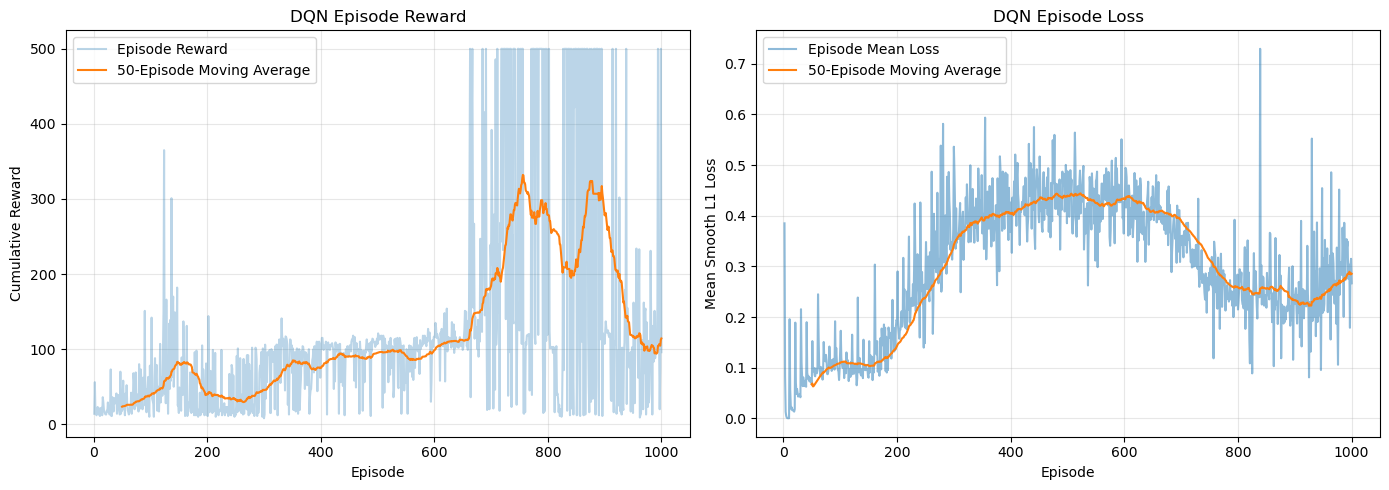

In [32]:

import numpy as np
import matplotlib.pyplot as plt

history = np.load(
    "cartpole_dqn_output/dqn_training_history.npz"
)

episode_rewards = history["episode_rewards"]
episode_losses = history["episode_losses"]

episodes = np.arange(1, len(episode_rewards) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    episodes, episode_rewards,
    alpha=0.3, label="Episode Reward"
)

if len(episode_rewards) >= 50:
    moving_reward = np.convolve(
        episode_rewards, np.ones(50) / 50, mode="valid"
    )
    axes[0].plot(
        np.arange(50, len(episode_rewards) + 1),
        moving_reward,
        label="50-Episode Moving Average"
    )

axes[0].set_title("DQN Episode Reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Cumulative Reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    episodes, episode_losses,
    alpha=0.5, label="Episode Mean Loss"
)

if len(episode_losses) >= 50:
    valid = np.isfinite(episode_losses)
    loss_values = np.where(valid, episode_losses, 0.0)
    loss_counts = np.convolve(
        valid.astype(float), np.ones(50), mode="valid"
    )
    loss_sums = np.convolve(
        loss_values, np.ones(50), mode="valid"
    )
    moving_loss = np.divide(
        loss_sums,
        loss_counts,
        out=np.full_like(loss_sums, np.nan),
        where=loss_counts > 0
    )
    axes[1].plot(
        np.arange(50, len(episode_losses) + 1),
        moving_loss,
        label="50-Episode Moving Average"
    )

axes[1].set_title("DQN Episode Loss")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Mean Smooth L1 Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
